# MIMIC-IV — Predizione del deterioramento clinico con NEWS-2 e Delta-NEWS
### Tesi Triennale in Ingegneria Biomedica

**Tesi:** *Progettazione di un modulo di interoperabilità per la sorveglianza automatizzata in terapia sub-intensiva*

**Domanda di ricerca:**
> È possibile progettare un modello di sorveglianza automatizzata che, a partire dai parametri
> vitali di routine sintetizzati nel NEWS-2 e nella sua evoluzione nel tempo (Delta-NEWS),
> predica il deterioramento clinico entro 24 ore, e che sia interoperabile, cioè applicabile
> con la stessa metodologia a basi dati cliniche eterogenee (MIMIC-IV, eICU-CRD, HiRID)?

**Interoperabilità:** i tre database usano schemi, codifiche e unità di misura diverse
(itemid in MIMIC-IV, nomi testuali in eICU-CRD, variableid in HiRID; temperature in °F e °C;
GCS verbale o totale). Ogni notebook traduce la propria sorgente nello stesso insieme comune di
20 variabili, con lo stesso endpoint e gli stessi modelli: è questo strato di armonizzazione che
rende il modello trasferibile da una base dati all'altra.

**Terapia sub-intensiva:** il modello è **pensato per** la sorveglianza automatizzata in terapia
sub-intensiva: il NEWS-2, su cui si basa, è nato proprio per il monitoraggio dei pazienti fuori dalla
terapia intensiva. Poiché non esistono database pubblici di terapia sub-intensiva con parametri vitali
ad alta frequenza, è stato **sviluppato e validato su** dati di terapia intensiva, il setting più vicino
disponibile. La validazione su dati di terapia sub-intensiva è lo sviluppo futuro naturale del lavoro.

**Ruolo nella tesi:** MIMIC-IV è il **confronto principale** rispetto a HiRID, il database di riferimento.
Su una parte di MIMIC-IV si fa anche la prova di interoperabilità con HL7 FHIR (`prova_fhir_mimic.ipynb`).

**Pipeline:**
1. Estrazione di parametri vitali e ossigeno supplementare da `chartevents` (campione casuale di 20.000 pazienti)
2. Pulizia outlier, ricampionamento a 10 minuti, imputazione dei valori mancanti
3. Calcolo NEWS-2 con scala AVPU standardizzata
4. Calcolo Delta-NEWS su finestra fissa di 6 ore
5. Costruzione endpoint composito (morte ICU + inizio vasopressori + intubazione) — finestra 24 h, solo insorgenza
6. Divisione train / validation / test **per paziente** (no data leakage)
7. Addestramento Random Forest, Logistic Regression, XGBoost
8. Scelta del modello sulla validazione (punteggio composito) e confronto con il NEWS-2 usato da solo
9. Valutazione: AUROC, AUPRC, Calibrazione, **Decision Curve Analysis**, SHAP
10. Intervalli di confidenza al 95% con bootstrap per paziente
11. Ricalibrazione isotonica delle probabilità
12. Tempo di anticipo degli allarmi
13. Consensus dei tre modelli (ensemble) e confronto con il modello scelto

## 1. Setup e Configurazione

In [1]:
import pandas as pd
import numpy as np
import os

CARTELLA_MIMIC  = "mimic-iv-3.1/"
CARTELLA_ICU    = CARTELLA_MIMIC + "icu/"
CARTELLA_HOSP   = CARTELLA_MIMIC + "hosp/"
CARTELLA_OUTPUT = "data_mimic/"
os.makedirs(CARTELLA_OUTPUT, exist_ok=True)

# Item ID dei parametri NEWS-2 in MIMIC-IV
ITEM_IDS = {
    220210: "freq_respiratoria",
    220277: "spo2",
    220179: "pressione_sistolica",   # non invasiva (bracciale)
    220050: "pressione_sistolica",   # NUOVO: invasiva (catetere arterioso), come i codici 100/600 di HiRID
    220045: "freq_cardiaca",
    223762: "temperatura",
    223900: "coscienza_gcs",    # GCS verbale (scala 1-5) — usato come proxy AVPU
}

# Ossigeno supplementare: tre fonti, come in HiRID (dispositivo, FiO2, flusso).
# 226732 (O2 Delivery Device) ha solo valori testuali (valuenum vuoto): conta la PRESENZA della riga.
ID_O2_DISPOSITIVO = 226732   # dispositivo (cannula, maschera, tubo endotracheale...): esiste solo se c'e' un dispositivo
ID_O2_FIO2        = 223835   # Inspired O2 Fraction (%): > 21 = ossigeno oltre l'aria ambiente
ID_O2_FLUSSO      = {223834, 227287}   # O2 Flow e O2 Flow (additional cannula), L/min: > 0
O2_ITEM_IDS = {ID_O2_DISPOSITIVO, ID_O2_FIO2} | ID_O2_FLUSSO
ID_TEMP_C = 223762   # temperatura in Celsius (già in ITEM_IDS)
ID_TEMP_F = 223761   # NUOVO: temperatura in Fahrenheit, l'84% delle registrazioni, da convertire in Celsius
ID_PA_INVASIVA = 220050
# Item ID vasopressori (per endpoint composito)
VASOPRESSORI_IDS = {221906, 221289, 221662, 222315, 221749}
LIBERO_VASO_ORE = 6   # un vasopressore conta come NUOVA insorgenza solo se nelle 6 ore precedenti non c'erano registrazioni per lo stesso ricovero (stessa soglia usata in HiRID)

print("=" * 60)
print("FASE 1 — Preparazione dataset MIMIC-IV")
print("=" * 60)


FASE 1 — Preparazione dataset MIMIC-IV


## 2. Estrazione Dati (Passo 1.1)
La tabella `chartevents` contiene centinaia di milioni di righe. Si filtrano in lettura solo i parametri
del NEWS-2 e si lavora su un **campione casuale** di 20.000 pazienti (seme fisso, riproducibile).

Oltre ai parametri vitali si leggono le tre fonti dell'**ossigeno supplementare**: dispositivo indicato, FiO2 e
flusso. Il dispositivo è registrato come testo, quindi si tengono anche le righe senza valore numerico: nella
prima versione un filtro le scartava e l'ossigeno risultava sempre 0.

In [2]:
print("\n[PASSO 1.1] Caricamento chartevents (a blocchi)...")

ID_VITALI_ESTRATTI = set(ITEM_IDS.keys()) | {ID_TEMP_F}   # i sei parametri di sempre + la temperatura in Fahrenheit

pezzi_vitali = []   # righe dei parametri vitali, blocco per blocco
pezzi_o2 = []       # righe delle tre fonti di ossigeno, blocco per blocco
n_totale = 0        # contatore delle righe lette

lettore = pd.read_csv(
    CARTELLA_ICU + "chartevents.csv.gz", compression="gzip",
    usecols=["subject_id", "stay_id", "charttime", "itemid", "value", "valuenum"],   # NUOVO: anche "value" (testo)
    dtype={"subject_id": "int32", "stay_id": "int32", "itemid": "int32",
           "value": "string", "valuenum": "float32"},
    chunksize=5_000_000,   # 5 milioni di righe alla volta
)
for blocco in lettore:
    n_totale += len(blocco)
    pezzi_o2.append(blocco[blocco["itemid"].isin(O2_ITEM_IDS)])   # tutte le righe di ossigeno, anche quelle senza numero
    vitali = blocco[blocco["itemid"].isin(ID_VITALI_ESTRATTI) & blocco["valuenum"].notna()]   # stessa regola di prima: solo valori numerici
    pezzi_vitali.append(vitali[["subject_id", "stay_id", "charttime", "itemid", "valuenum"]])

chartevents = pd.concat(pezzi_vitali, ignore_index=True)
_o2 = pd.concat(pezzi_o2, ignore_index=True)
del pezzi_vitali, pezzi_o2
print(f"  chartevents letto: {n_totale:,} righe")

# --- Ossigeno supplementare (CORRETTO) ---
# Prima ogni riga del dispositivo contava come ossigeno. Ma il 19,2% di quelle righe non ha un
# dispositivo indicato (testo "None", che pandas legge come valore mancante): ora valgono 0 e
# interrompono la persistenza di 4 ore, come "RA"/"room air" in eICU-CRD.
_o2["_o2"] = np.nan   # NaN = riga che non dice nulla sull'ossigeno
disp = _o2["itemid"] == ID_O2_DISPOSITIVO
_o2.loc[disp, "_o2"] = _o2.loc[disp, "value"].notna().astype(int)   # dispositivo indicato = 1, nessun dispositivo = 0
fio2_alta = (_o2["itemid"] == ID_O2_FIO2) & (_o2["valuenum"] > 21)     # invariato: FiO2 sopra l'aria ambiente
flusso = _o2["itemid"].isin(ID_O2_FLUSSO) & (_o2["valuenum"] > 0)       # invariato: flusso positivo
_o2.loc[fio2_alta | flusso, "_o2"] = 1
o2_eventi = _o2.dropna(subset=["_o2"])[["subject_id", "stay_id", "charttime", "_o2"]].copy()
o2_eventi = o2_eventi.groupby(["subject_id", "stay_id", "charttime"], as_index=False)["_o2"].max()   # se nello stesso istante una fonte dice 1, vale 1
del _o2
print(f"  Registrazioni di ossigeno: {len(o2_eventi):,} (di cui con ossigeno: {int(o2_eventi['_o2'].sum()):,})")

# --- Campionamento: STESSI 20.000 pazienti di prima ---
# Gli ID si prendono escludendo le righe in Fahrenheit: così l'ordine degli ID è identico alla
# versione precedente e il seed 42 estrae esattamente gli stessi pazienti.
_rng = np.random.default_rng(42)
_id_unici = chartevents.loc[~chartevents["itemid"].isin([ID_TEMP_F, ID_PA_INVASIVA]), "subject_id"].unique()
print(f"  Pazienti ICU da cui si campiona: {len(_id_unici):,}")
pazienti_campione = _rng.choice(_id_unici, size=min(20000, len(_id_unici)), replace=False)
chartevents = chartevents[chartevents["subject_id"].isin(pazienti_campione)].copy()
o2_eventi = o2_eventi[o2_eventi["subject_id"].isin(pazienti_campione)]

# --- Temperatura (CORRETTA): Fahrenheit convertiti in Celsius ---
mask_f = chartevents["itemid"] == ID_TEMP_F
chartevents.loc[mask_f, "valuenum"] = (chartevents.loc[mask_f, "valuenum"] - 32) * 5 / 9   # °C = (°F − 32) × 5/9
chartevents.loc[mask_f, "itemid"] = ID_TEMP_C   # da qui in poi sono temperature in Celsius come le altre
print(f"  Temperature convertite da Fahrenheit: {int(mask_f.sum()):,}")
print(f"  Campione: {len(chartevents):,} righe, {len(pazienti_campione):,} pazienti")


[PASSO 1.1] Caricamento chartevents (a blocchi)...


  chartevents letto: 432,997,491 righe


  Registrazioni di ossigeno: 2,286,690 (di cui con ossigeno: 1,890,706)


  Pazienti ICU da cui si campiona: 65,366


  Temperature convertite da Fahrenheit: 620,533
  Campione: 11,816,466 righe, 20,000 pazienti


## 3. Pivoting (Passo 1.2)
Trasformazione da formato verticale (una riga = un parametro) a orizzontale (una riga = un istante temporale).


In [3]:
print("\n[PASSO 1.2] Pivot verticale -> orizzontale...")

chartevents["parametro"] = chartevents["itemid"].map(ITEM_IDS)
chartevents["charttime"] = pd.to_datetime(chartevents["charttime"])

df = chartevents.pivot_table(
    index=["subject_id", "stay_id", "charttime"],
    columns="parametro",
    values="valuenum",
    aggfunc="mean"
).reset_index()
df.columns.name = None

del chartevents

# Ossigeno supplementare: il paziente e' "in ossigenoterapia" se nelle 4 ore precedenti dello stesso
# ricovero esiste una registrazione (dispositivo, FiO2 > 21, flusso > 0). Le 4 ore riflettono ogni
# quanto si registra il dispositivo; senza persistenza il flag varrebbe 1 solo negli istanti esatti.
o2_eventi["charttime"] = pd.to_datetime(o2_eventi["charttime"])

o2_eventi = o2_eventi.sort_values("charttime")
df = df.sort_values("charttime").reset_index(drop=True)
_o2_stato = pd.merge_asof(
    df[["subject_id", "stay_id", "charttime"]], o2_eventi,
    on="charttime", by=["subject_id", "stay_id"],
    direction="backward", tolerance=pd.Timedelta("4h"))
df["ossigeno_supplementare"] = _o2_stato["_o2"].fillna(0).astype(int).values
print(f"  Ossigeno supplementare presente nel {df['ossigeno_supplementare'].mean()*100:.1f}% delle righe")

print(f"  Dataset pivot: {len(df):,} righe, {len(df.columns)} colonne")
print(f"  Pazienti unici: {df['subject_id'].nunique():,}")



[PASSO 1.2] Pivot verticale -> orizzontale...


  Ossigeno supplementare presente nel 65.6% delle righe
  Dataset pivot: 3,974,919 righe, 10 colonne
  Pazienti unici: 20,000


## 4. Pulizia Outlier, Ricampionamento e Imputazione (Passi 1.3 – 1.4)
**Outlier assoluti**: valori fisiologicamente impossibili → sostituiti con NaN.

**Ricampionamento a 10 minuti** sulle sole misure vere: media per i parametri continui, massimo per l'ossigeno
(1 se nel blocco c'è ossigeno). Avviene prima dell'imputazione, così la media non mescola misure vere e valori
inventati.

**Imputazione**: flag `_mancante` (1 = nel blocco non c'è nessuna misura vera) → riporto dell'ultimo valore vero
fino a 4 ore → valori fisiologici fissi per ciò che resta (stessi valori di HiRID ed eICU-CRD; GCS verbale 5 = vigile).

In [4]:
print("\n[PASSO 1.3] Pulizia outlier...")
filtri = {
    "freq_respiratoria":  (4,   60),
    "spo2":               (50,  100),
    "pressione_sistolica":(40,  300),
    "freq_cardiaca":      (10,  300),
    "temperatura":        (25,  45),
    "coscienza_gcs":      (1,   5),   # GCS verbale MIMIC-IV
}
for colonna, (minimo, massimo) in filtri.items():
    if colonna in df.columns:
        n_prima = df[colonna].notna().sum()
        df.loc[(df[colonna] < minimo) | (df[colonna] > massimo), colonna] = np.nan
        n_rimossi = n_prima - df[colonna].notna().sum()
        if n_rimossi > 0:
            print(f"  {colonna}: rimossi {n_rimossi:,} valori fuori range")

# Filtro artefatti temporali: stesse soglie di HiRID ed eICU-CRD
# (salti fisiologicamente impossibili in 10 minuti o meno)
df = df.sort_values(["subject_id", "stay_id", "charttime"])
df["delta_tempo_min"] = df.groupby(["subject_id", "stay_id"])["charttime"].diff().dt.total_seconds() / 60   # minuti dalla lettura precedente

delta_fc = df.groupby(["subject_id", "stay_id"])["freq_cardiaca"].diff().abs()   # variazione di FC rispetto alla lettura precedente
salto_fc = (delta_fc > 50) & (df["delta_tempo_min"] <= 10)
df.loc[salto_fc, "freq_cardiaca"] = np.nan

delta_pa = df.groupby(["subject_id", "stay_id"])["pressione_sistolica"].diff().abs()   # stesso controllo sulla pressione
salto_pa = (delta_pa > 60) & (df["delta_tempo_min"] <= 10)
df.loc[salto_pa, "pressione_sistolica"] = np.nan

print(f"  Rimossi {int(salto_fc.sum()):,} artefatti FC, {int(salto_pa.sum()):,} artefatti pressione")
df = df.drop(columns=["delta_tempo_min"])   # colonna di appoggio non più necessaria


[PASSO 1.3] Pulizia outlier...
  freq_respiratoria: rimossi 10,728 valori fuori range
  spo2: rimossi 917 valori fuori range
  pressione_sistolica: rimossi 1,025 valori fuori range
  freq_cardiaca: rimossi 1,095 valori fuori range
  temperatura: rimossi 620 valori fuori range


  Rimossi 719 artefatti FC, 1,354 artefatti pressione


In [5]:
print("Ricampionamento a 10 minuti (sulle sole misure vere)...")
parametri = ["freq_respiratoria", "spo2", "pressione_sistolica",
             "freq_cardiaca", "temperatura", "coscienza_gcs"]

df["charttime"] = pd.to_datetime(df["charttime"])
df = df.set_index("charttime")
agg = {c: "mean" for c in parametri}    # media delle sole misure vere: i NaN vengono ignorati
agg["ossigeno_supplementare"] = "max"   # 1 se nel blocco c'è ossigeno (ha già la persistenza di 4 ore)
df = (
    df.groupby(["subject_id", "stay_id"]).resample("10min").agg(agg)
    .dropna(how="all").reset_index()    # scarta i blocchi senza nessuna misura
)
print(f"  Righe dopo ricampionamento: {len(df):,}")

print("\n[PASSO 1.4] Flag mancanti e imputazione...")
df = df.sort_values(["subject_id", "stay_id", "charttime"])

# Flag: 1 = in questi 10 minuti non c'è nessuna misura vera del parametro
for col in parametri:
    df[f"{col}_mancante"] = df[col].isna().astype(int)

# Riporto dell'ultimo valore vero fino a 4 ore (stessa regola di HiRID ed eICU-CRD)
LIMITE_FFILL = pd.Timedelta(hours=4)
chiavi = [df["subject_id"], df["stay_id"]]
for col in parametri:   # tutti e sei i parametri (entro 4 ore), come in HiRID
    t_misura = df["charttime"].where(df[col].notna()).groupby(chiavi).ffill()   # istante dell'ultima misura vera
    riempito = df.groupby(["subject_id", "stay_id"])[col].ffill()              # ultimo valore vero riportato avanti
    df[col] = riempito.where(df["charttime"] - t_misura <= LIMITE_FFILL)       # valido solo se ha al massimo 4 ore

print("  Blocchi con valore vero, prima dei valori fissi:")
for col in parametri:
    print(f"    {col:22s} {100 * df[col].notna().mean():5.1f}%")

# Valori fisiologici fissi per ciò che resta (GCS verbale: 5 = vigile)
valori_fisiologici = {
    "freq_respiratoria": 16, "spo2": 97, "pressione_sistolica": 120,
    "freq_cardiaca": 70, "temperatura": 37.0, "coscienza_gcs": 5,
}
for col in parametri:
    df[col] = df[col].fillna(valori_fisiologici[col])
print("  Imputazione completata.")

Ricampionamento a 10 minuti (sulle sole misure vere)...


  Righe dopo ricampionamento: 2,915,210

[PASSO 1.4] Flag mancanti e imputazione...


  Blocchi con valore vero, prima dei valori fissi:
    freq_respiratoria       99.0%
    spo2                    99.1%
    pressione_sistolica     96.6%
    freq_cardiaca           99.7%
    temperatura             92.5%
    coscienza_gcs           86.4%
  Imputazione completata.


## 5. Calcolo NEWS-2 con scala AVPU standardizzata (Passo 1.5)

**Standardizzazione AVPU:**
MIMIC-IV fornisce il GCS verbale (scala 1–5). La mappatura verso AVPU è:
- GCS verbale = 5 → Alert (A) → **0 punti NEWS-2**
- GCS verbale ≤ 4 → qualsiasi compromissione → **3 punti NEWS-2**

Questa convenzione è coerente con eICU-CRD (dove si usa GCS totale con soglia ≥ 14 = Alert)
e consente il confronto diretto tra i tre database (HiRID usa la stessa soglia di eICU-CRD sul GCS totale). Fonte: Royal College of Physicians, NEWS-2 (2017).

In [6]:
print("\n[PASSO 1.5] Calcolo NEWS-2 con AVPU standardizzato...")

def calcola_news2(row):
    """
    NEWS-2 secondo Royal College of Physicians (2017).
    Punteggio 0-20 (più alto = paziente più grave).
    Scala AVPU: GCS verbale MIMIC-IV (1-5)
      - 5 = Alert (0 pt)
      - ≤ 4 = compromissione coscienza (3 pt)
    """
    score = 0

    # 1. Frequenza respiratoria
    fr = row.get("freq_respiratoria", 16)
    if   fr <= 8:  score += 3
    elif fr <= 11: score += 1
    elif fr <= 20: score += 0
    elif fr <= 24: score += 2
    else:          score += 3

    # 2. SpO2
    spo2 = row.get("spo2", 97)
    if   spo2 <= 91: score += 3
    elif spo2 <= 93: score += 2
    elif spo2 <= 95: score += 1

    # 3. Ossigeno supplementare
    if row.get("ossigeno_supplementare", 0) > 0:
        score += 2

    # 4. Pressione arteriosa sistolica
    pa = row.get("pressione_sistolica", 120)
    if   pa <= 90:  score += 3
    elif pa <= 100: score += 2
    elif pa <= 110: score += 1
    elif pa <= 219: score += 0
    else:           score += 3

    # 5. Frequenza cardiaca
    fc = row.get("freq_cardiaca", 70)
    if   fc <= 40:  score += 3
    elif fc <= 50:  score += 1
    elif fc <= 90:  score += 0
    elif fc <= 110: score += 1
    elif fc <= 130: score += 2
    else:           score += 3

    # 6. Livello di coscienza — proxy AVPU tramite GCS verbale (MIMIC-IV)
    #    GCS verbale 5 = Alert → 0 pt
    #    GCS verbale ≤ 4 = compromissione → 3 pt  (V / P / U in AVPU)
    gcs = row.get("coscienza_gcs", 5)
    if gcs < 5:
        score += 3

    # 7. Temperatura
    temp = row.get("temperatura", 37)
    if   temp <= 35.0: score += 3
    elif temp <= 36.0: score += 1
    elif temp <= 38.0: score += 0
    elif temp <= 39.0: score += 1
    else:              score += 2

    return score

df["news2"] = df.apply(calcola_news2, axis=1)
print(f"  NEWS-2 calcolato. Media: {df['news2'].mean():.2f} | Max: {df['news2'].max()}")



[PASSO 1.5] Calcolo NEWS-2 con AVPU standardizzato...


  NEWS-2 calcolato. Media: 5.56 | Max: 20


## 6. Delta-NEWS su finestra fissa di 6 ore (Passo 1.6)

Il **Delta-NEWS** affianca il NEWS-2 istantaneo: mentre il NEWS-2 fotografa lo stato attuale,
il Delta-NEWS cattura la **traiettoria** del paziente:
un paziente stabile a NEWS=7 e uno che è salito da 4 a 7 nelle ultime 6 ore
hanno lo stesso punteggio istantaneo ma rischi molto diversi.

**Formula:**
```
delta_news_6h(t) = NEWS-2(t) − NEWS-2(più vecchio nella finestra [t-6h, t])
```
Valore positivo → peggioramento; valore negativo → miglioramento.

Vengono calcolate anche le feature di rolling window (max, min, media, std su 6 ore)



In [7]:
print("\n[PASSO 1.6] Calcolo Delta-NEWS e feature temporali...")

df = df.sort_values(["subject_id", "stay_id", "charttime"])
df = df.set_index("charttime")

def features_temporali(gruppo):
    gruppo = gruppo.sort_index()
    rolling = gruppo["news2"].rolling("360min", min_periods=1)

    # Feature di rolling window (già presenti nel codice originale)
    gruppo["news2_max_6h"]   = rolling.max()
    gruppo["news2_min_6h"]   = rolling.min()
    gruppo["news2_media_6h"] = rolling.mean()
    gruppo["news2_std_6h"]   = rolling.std().fillna(0)

    # Delta-NEWS istantaneo (variazione rispetto alla misurazione precedente)
    gruppo["delta_news"] = gruppo["news2"].diff().fillna(0)

    # ── NUOVO: Delta-NEWS su finestra FISSA di 6 ore ──────────────────────
    # Per ogni istante t, prende il NEWS più vecchio nella finestra [t-6h, t]
    # e calcola la differenza rispetto al valore attuale.
    
    news_6h_fa = (
        gruppo["news2"]
        .rolling("360min", min_periods=2)
        .apply(lambda x: x.iloc[0], raw=False)   # primo valore = ~6h fa
    )
    gruppo["delta_news_6h"] = (gruppo["news2"] - news_6h_fa).fillna(0)

    # Flag parametri mancanti aggregato
    cols_mancanti = [c for c in gruppo.columns if c.endswith("_mancante")]
    gruppo["n_parametri_mancanti"] = gruppo[cols_mancanti].sum(axis=1)

    return gruppo

df = (
    df.groupby(["subject_id", "stay_id"], group_keys=True)
      .apply(features_temporali, include_groups=False)
      .reset_index()
)

print("  Feature temporali calcolate:")
print(f"    delta_news (istantaneo) — media: {df['delta_news'].mean():.3f}")
print(f"    delta_news_6h (6h)      — media: {df['delta_news_6h'].mean():.3f}")



[PASSO 1.6] Calcolo Delta-NEWS e feature temporali...


  Feature temporali calcolate:
    delta_news (istantaneo) — media: 0.010
    delta_news_6h (6h)      — media: 0.180


## 7. Endpoint Composito — finestra 24 ore (Passo 1.7)
Tre fonti di evento. La **morte** conta solo se avviene durante la degenza in terapia intensiva: chi è morto lo
dice `hospital_expire_flag` (1 = deceduto in ospedale, ricovero collegato alla degenza ICU tramite `hadm_id`),
l'orario viene da `deathtime` e deve cadere tra ingresso e uscita dalla terapia intensiva. Per i pochi decessi
senza `deathtime` l'orario è la fine dell'ultima degenza ICU, se il paziente non è uscito dall'ospedale dopo di essa
(come in eICU-CRD). Nella prima versione si usava solo `deathtime` e l'unione era fatta per paziente invece che per
ricovero.

Il vasopressore conta come **insorgenza**: `inputevents` ha una riga per ogni
cambio di dose/velocità della stessa infusione (verificato: 755.919 righe, 18 per ricovero in media,
l'85% con un'altra riga nelle 6 ore precedenti), quindi contarle tutte farebbe risultare "deteriorato"
un paziente per l'intera durata della terapia. Teniamo solo la prima riga dopo almeno `LIBERO_VASO_ORE`
ore senza vasopressori. L'intubazione invece resta com'era: `procedureevents` registra episodi con
inizio e fine propri (verificato: 1,11 episodi per ricovero in media, il 98% separato da più di un'ora
dall'episodio precedente), non ha lo stesso problema.


In [8]:
print("\n[PASSO 1.7] Costruzione endpoint composito (24h)...")

FINESTRA_ORE = 24

# A. Morte intra-ICU
# Chi è morto lo dice hospital_expire_flag (1 = deceduto in ospedale); l'orario viene da deathtime.
# Verificato su tutto MIMIC-IV: nessun ricovero ha deathtime con flag 0, ma 11 hanno flag 1 e deathtime vuoto.
# Per questi 11 l'orario si ricava dalla degenza ICU, come in eICU-CRD: se l'uscita dall'ospedale (dischtime)
# non è successiva alla fine dell'ultima degenza ICU, il paziente è morto in terapia intensiva e l'orario è
# la fine di quella degenza (outtime). dischtime non si usa come orario: in 6 casi è PRIMA della fine della
# degenza ICU (dato incoerente) e metterebbe la morte a metà di un ricovero ancora monitorato.
admissions_df = pd.read_csv(
    CARTELLA_HOSP + "admissions.csv.gz", compression="gzip",
    usecols=["hadm_id", "deathtime", "dischtime", "hospital_expire_flag"]
)
admissions_df = admissions_df[admissions_df["hospital_expire_flag"] == 1].copy()   # solo i ricoveri terminati con il decesso
admissions_df["deathtime"] = pd.to_datetime(admissions_df["deathtime"])
admissions_df["dischtime"] = pd.to_datetime(admissions_df["dischtime"])

icustays_df = pd.read_csv(
    CARTELLA_ICU + "icustays.csv.gz", compression="gzip",
    usecols=["subject_id", "hadm_id", "stay_id", "intime", "outtime"]
)
icustays_df["intime"]  = pd.to_datetime(icustays_df["intime"])
icustays_df["outtime"] = pd.to_datetime(icustays_df["outtime"])

icu_info = icustays_df.merge(admissions_df, on="hadm_id", how="inner")   # degenze ICU dei ricoveri con decesso

# 1) Orario registrato: conta se cade durante la degenza ICU
con_orario = icu_info[icu_info["deathtime"].notna() &
                      (icu_info["deathtime"] >= icu_info["intime"]) &
                      (icu_info["deathtime"] <= icu_info["outtime"])].copy()
con_orario["evento_time"] = con_orario["deathtime"]

# 2) Orario mancante: ultima degenza ICU del ricovero, se l'ospedale non continua dopo la sua fine
senza_orario = icu_info[icu_info["deathtime"].isna()].sort_values("outtime").groupby("hadm_id").tail(1)
senza_orario = senza_orario[senza_orario["dischtime"] <= senza_orario["outtime"]].copy()
senza_orario["evento_time"] = senza_orario["outtime"]
print(f"  Decessi in ospedale senza deathtime: {int(admissions_df['deathtime'].isna().sum())}, "
      f"di cui attribuiti a una degenza ICU (orario = fine degenza): {len(senza_orario)}")

morti_icu = pd.concat([con_orario, senza_orario])[["subject_id", "stay_id", "evento_time"]].copy()
morti_icu["tipo_evento"] = "morte_icu"
morti_icu = morti_icu[morti_icu["subject_id"].isin(pazienti_campione)]   # conta solo i decessi del campione (prima stampava il totale di MIMIC)

# B. Vasopressori (solo insorgenze)
inputevents_df = pd.read_csv(
    CARTELLA_ICU + "inputevents.csv.gz", compression="gzip",
    usecols=["subject_id", "stay_id", "starttime", "itemid"]
)
inputevents_df["starttime"] = pd.to_datetime(inputevents_df["starttime"])
vasopressori = (
    inputevents_df[inputevents_df["itemid"].isin(VASOPRESSORI_IDS)]
    [inputevents_df["subject_id"].isin(pazienti_campione)]
    .rename(columns={"starttime": "evento_time"})
    [["subject_id", "stay_id", "evento_time"]]
    .dropna(subset=["evento_time"])
    .sort_values(["subject_id", "stay_id", "evento_time"])
    .copy()
)
# Insorgenza: teniamo solo la prima riga di ogni ricovero e le righe che arrivano dopo almeno
# LIBERO_VASO_ORE ore senza vasopressori (qualunque farmaco) per lo stesso ricovero — altrimenti
# ogni cambio di dose della stessa infusione conterebbe come un nuovo deterioramento.
_ore_dal_precedente = (
    vasopressori["evento_time"] - vasopressori.groupby(["subject_id", "stay_id"])["evento_time"].shift(1)
).dt.total_seconds() / 3600
vasopressori = vasopressori[_ore_dal_precedente.isna() | (_ore_dal_precedente > LIBERO_VASO_ORE)].copy()
vasopressori["tipo_evento"] = "vasopressore"

# C. Intubazione
procedureevents_df = pd.read_csv(
    CARTELLA_ICU + "procedureevents.csv.gz", compression="gzip",
    usecols=["subject_id", "stay_id", "starttime", "itemid"]
)
procedureevents_df["starttime"] = pd.to_datetime(procedureevents_df["starttime"])
intubazioni = (
    procedureevents_df[procedureevents_df["itemid"] == 225792]
    [procedureevents_df["subject_id"].isin(pazienti_campione)]
    .rename(columns={"starttime": "evento_time"})
    [["subject_id", "stay_id", "evento_time"]].copy()
)
intubazioni["tipo_evento"] = "intubazione"

tutti_eventi = pd.concat([morti_icu, vasopressori, intubazioni], ignore_index=True)
print(f"  Decessi intra-ICU : {len(morti_icu):,}")
print(f"  Avvii vasopressori: {len(vasopressori):,}")
print(f"  Intubazioni       : {len(intubazioni):,}")

# Assegnazione etichetta: deterioramento=1 se evento in (t, t+24h]
df["charttime"] = pd.to_datetime(df["charttime"])
merged = df[["subject_id", "stay_id", "charttime"]].merge(
    tutti_eventi, on=["subject_id", "stay_id"], how="left"
)
merged["ore_al_evento"] = (
    merged["evento_time"] - merged["charttime"]
).dt.total_seconds() / 3600

merged["evento_in_24h"] = (
    merged["ore_al_evento"] > 0
) & (merged["ore_al_evento"] <= FINESTRA_ORE)

etichette = (
    merged.groupby(["subject_id", "stay_id", "charttime"])["evento_in_24h"]
    .any().astype(int).reset_index()
    .rename(columns={"evento_in_24h": "deterioramento"})
)
df = df.merge(etichette, on=["subject_id", "stay_id", "charttime"], how="left")
df["deterioramento"] = df["deterioramento"].fillna(0).astype(int)

tasso = df["deterioramento"].mean() * 100
print(f"\n  Tasso di deterioramento nel dataset: {tasso:.1f}%")



[PASSO 1.7] Costruzione endpoint composito (24h)...


  Decessi in ospedale senza deathtime: 11, di cui attribuiti a una degenza ICU (orario = fine degenza): 6


C:\Users\marac\AppData\Local\Temp\ipykernel_63680\3214900380.py:53: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  inputevents_df[inputevents_df["itemid"].isin(VASOPRESSORI_IDS)]


C:\Users\marac\AppData\Local\Temp\ipykernel_63680\3214900380.py:77: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  procedureevents_df[procedureevents_df["itemid"] == 225792]


  Decessi intra-ICU : 2,202
  Avvii vasopressori: 21,930
  Intubazioni       : 10,726



  Tasso di deterioramento nel dataset: 15.4%


## 8. Split Train / Validation / Test per Paziente (Passo 1.8)
Lo split avviene a livello di `subject_id` (paziente), non di riga.
Questo garantisce che nessun paziente compaia in due partizioni diverse
(prevenzione del data leakage inter-paziente).
Proporzione: 60% train — 20% validation — 20% test.


In [9]:
from sklearn.model_selection import train_test_split

print("\n[PASSO 1.8] Split train/validation/test per paziente...")

# Feature set — stesse 20 variabili armonizzate in tutti e tre i database
FEATURES = [
    # Parametri vitali (correnti)
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura", "ossigeno_supplementare",
    # Score clinico
    "news2",
    # Feature temporali (rolling 6h)
    "news2_max_6h", "news2_min_6h", "news2_media_6h", "news2_std_6h",
    # Delta-NEWS — evoluzione del NEWS-2 nel tempo
    "delta_news",          # variazione istantanea
    "delta_news_6h",       # variazione su finestra fissa di 6 ore
    # Qualità del dato
    "n_parametri_mancanti",
    # Flag mancanza (informazione clinica implicita)
    "freq_respiratoria_mancante", "spo2_mancante", "pressione_sistolica_mancante",
    "freq_cardiaca_mancante", "temperatura_mancante", "coscienza_gcs_mancante",
]

df_model = df[FEATURES + ["deterioramento", "subject_id"]].dropna(subset=["deterioramento"])

pazienti_unici = df_model["subject_id"].unique()
train_ids, temp_ids = train_test_split(pazienti_unici, test_size=0.40, random_state=42)
val_ids,   test_ids = train_test_split(temp_ids,       test_size=0.50, random_state=42)

df_train = df_model[df_model["subject_id"].isin(train_ids)]
df_val   = df_model[df_model["subject_id"].isin(val_ids)]
df_test  = df_model[df_model["subject_id"].isin(test_ids)]

X_train = df_train[FEATURES]; y_train = df_train["deterioramento"]
X_val   = df_val[FEATURES];   y_val   = df_val["deterioramento"]
X_test  = df_test[FEATURES];  y_test  = df_test["deterioramento"]

print(f"  Train: {len(X_train):,} righe | {len(train_ids):,} pazienti")
print(f"  Val  : {len(X_val):,} righe | {len(val_ids):,} pazienti")
print(f"  Test : {len(X_test):,} righe | {len(test_ids):,} pazienti")
print(f"  Overlap pazienti train/test: {len(set(train_ids) & set(test_ids))} [deve essere 0]")



[PASSO 1.8] Split train/validation/test per paziente...


  Train: 1,743,671 righe | 12,000 pazienti
  Val  : 593,163 righe | 4,000 pazienti
  Test : 578,376 righe | 4,000 pazienti
  Overlap pazienti train/test: 0 [deve essere 0]


Cosa mostra il blocco:
Nella parte testuale — i check numerici:

- Dimensioni del dataset e anteprima delle prime 5 righe
- Statistiche descrittive dei parametri vitali (media, min, max — così vedi se i valori hanno senso)
- Quanti valori mancanti restano dopo l'imputazione (deve essere 0)
- Bilanciamento dell'endpoint (quanti pazienti si deteriorano)
- Conferma che lo split non ha data leakage

Nei grafici — 6 visualizzazioni:

- Distribuzione del NEWS-2 con le soglie RCP segnate in arancione e rosso
- Distribuzione del Delta-NEWS 6h (ci si aspetta una distribuzione centrata su 0, con una coda a destra per i deterioramenti)
- Bilanciamento delle classi
- NEWS-2 separato per stabili vs deteriorati (deve vedersi differenza)
- Delta-NEWS separato per classe (mostra se la traiettoria del NEWS-2 separa le due classi)
- Traiettoria nel tempo di un paziente campione

In [10]:
# =============================================================================
# per vedere come si presentano i dati dopo la pulizia.
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import os
os.makedirs("outputs", exist_ok=True)

print("=" * 65)
print("  DIAGNOSTICA DEL DATASET — MIMIC-IV")
print("=" * 65)

# ─────────────────────────────────────────────────────────────────
# 1. FORMA DEL DATASET E ANTEPRIMA
# ─────────────────────────────────────────────────────────────────
print(f"\n[1] DIMENSIONI")
print(f"    Righe totali     : {len(df):,}")
print(f"    Colonne totali   : {len(df.columns)}")
print(f"    Pazienti unici   : {df['subject_id'].nunique():,}")
print(f"    Ricoveri unici   : {df['stay_id'].nunique():,}")

print(f"\n[2] PRIME 5 RIGHE DEL DATASET PULITO")
print(df[[
    "subject_id", "stay_id", "charttime",
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura",
    "news2", "delta_news_6h", "deterioramento"
]].head(5).to_string(index=False))

# ─────────────────────────────────────────────────────────────────
# 2. STATISTICHE DESCRITTIVE DEI PARAMETRI VITALI
# ─────────────────────────────────────────────────────────────────
print(f"\n[3] STATISTICHE DESCRITTIVE (parametri vitali dopo pulizia)")
cols_vitali = [
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura"
]
print(df[cols_vitali].describe().round(2).to_string())

# ─────────────────────────────────────────────────────────────────
# 3. CONTROLLO VALORI MANCANTI
# ─────────────────────────────────────────────────────────────────
print(f"\n[4] VALORI MANCANTI dopo imputazione")
nan_counts = df[FEATURES].isna().sum()
if nan_counts.sum() == 0:
    print("    ✓ Nessun valore mancante nelle feature del modello.")
else:
    print("    ✗ ATTENZIONE — valori mancanti trovati:")
    print(nan_counts[nan_counts > 0].to_string())

# ─────────────────────────────────────────────────────────────────
# 4. DISTRIBUZIONE DELL'ENDPOINT
# ─────────────────────────────────────────────────────────────────
n_tot   = len(df)
n_det   = df["deterioramento"].sum()
n_stab  = n_tot - n_det
tasso   = n_det / n_tot * 100

print(f"\n[5] ENDPOINT — deterioramento nelle 24h")
print(f"    Pazienti stabili     : {n_stab:,}  ({100 - tasso:.1f}%)")
print(f"    Pazienti deteriorati : {n_det:,}  ({tasso:.1f}%)")
if tasso < 5:
    print("    ⚠️  Dataset molto sbilanciato — class_weight='balanced' è essenziale.")
elif tasso < 20:
    print("    ✓ Sbilanciamento moderato — gestito con class_weight='balanced'.")
else:
    print("    ✓ Dataset ragionevolmente bilanciato.")

# ─────────────────────────────────────────────────────────────────
# 5. DISTRIBUZIONE NEWS-2 E DELTA-NEWS
# ─────────────────────────────────────────────────────────────────
print(f"\n[6] NEWS-2 e Delta-NEWS")
print(f"    NEWS-2  — media: {df['news2'].mean():.2f}  |  "
      f"mediana: {df['news2'].median():.0f}  |  max: {df['news2'].max()}")
print(f"    Delta-NEWS 6h — media: {df['delta_news_6h'].mean():.3f}  |  "
      f"std: {df['delta_news_6h'].std():.3f}")

# ─────────────────────────────────────────────────────────────────
# 6. CONTROLLO SPLIT (no data leakage)
# ─────────────────────────────────────────────────────────────────
print(f"\n[7] CONTROLLO SPLIT — nessun paziente in comune tra train e test")
overlap = len(set(train_ids) & set(test_ids))
if overlap == 0:
    print("    ✓ Nessun paziente in comune — split corretto.")
else:
    print(f"    ✗ ERRORE GRAVE: {overlap} pazienti in comune tra train e test!")

print(f"\n    Train : {len(X_train):>8,} righe  ({len(train_ids):,} pazienti)")
print(f"    Val   : {len(X_val):>8,} righe  ({len(val_ids):,} pazienti)")
print(f"    Test  : {len(X_test):>8,} righe  ({len(test_ids):,} pazienti)")

# ─────────────────────────────────────────────────────────────────
# 7. GRAFICI — visualizza i dati
# ─────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

# Grafico 1 — Distribuzione NEWS-2
ax1 = fig.add_subplot(gs[0, 0])
df["news2"].hist(bins=20, ax=ax1, color="#4C72B0", edgecolor="white")
ax1.axvline(5, color="orange", linestyle="--", linewidth=1.5, label="Soglia RCP ≥5")
ax1.axvline(7, color="red",    linestyle="--", linewidth=1.5, label="Soglia RCP ≥7")
ax1.set_title("Distribuzione NEWS-2")
ax1.set_xlabel("Punteggio NEWS-2"); ax1.set_ylabel("Frequenza")
ax1.legend(fontsize=8)

# Grafico 2 — Distribuzione Delta-NEWS 6h
ax2 = fig.add_subplot(gs[0, 1])
df["delta_news_6h"].clip(-6, 6).hist(bins=25, ax=ax2, color="#55A868", edgecolor="white")
ax2.axvline(0, color="black", linestyle="-", linewidth=1)
ax2.set_title("Distribuzione Delta-NEWS 6h")
ax2.set_xlabel("Variazione NEWS-2 nelle ultime 6h")
ax2.set_ylabel("Frequenza")

# Grafico 3 — Bilanciamento classi
ax3 = fig.add_subplot(gs[0, 2])
etichette_classi = ["Stabile\n(0)", "Deterioramento\n(1)"]
valori_classi    = [n_stab, n_det]
colori_classi    = ["#4C72B0", "#C44E52"]
bars = ax3.bar(etichette_classi, valori_classi, color=colori_classi, edgecolor="white", width=0.5)
for bar, val in zip(bars, valori_classi):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + n_tot * 0.005,
             f"{val:,}\n({val/n_tot*100:.1f}%)",
             ha="center", va="bottom", fontsize=9)
ax3.set_title("Bilanciamento Classi")
ax3.set_ylabel("Numero di osservazioni")

# Grafico 4 — NEWS-2 medio: stabili vs deteriorati
ax4 = fig.add_subplot(gs[1, 0])
for classe, colore, etichetta in zip(
    [0, 1], ["#4C72B0", "#C44E52"], ["Stabile (0)", "Deterioramento (1)"]
):
    df[df["deterioramento"] == classe]["news2"].hist(
        bins=20, ax=ax4, alpha=0.65,
        color=colore, edgecolor="white", label=etichetta
    )
ax4.set_title("NEWS-2 per classe")
ax4.set_xlabel("Punteggio NEWS-2")
ax4.set_ylabel("Frequenza")
ax4.legend()


# Grafico 5 — Delta-NEWS 6h: stabili vs deteriorati
ax5 = fig.add_subplot(gs[1, 1])
for classe, colore, etichetta in zip([0, 1], ["#4C72B0", "#C44E52"],
                                      ["Stabile", "Deterioramento"]):
    df[df["deterioramento"] == classe]["delta_news_6h"].clip(-6, 6).hist(
        bins=20, ax=ax5, alpha=0.65, color=colore,
        edgecolor="white", label=etichetta
    )
ax5.axvline(0, color="black", linewidth=1)
ax5.set_title("Delta-NEWS 6h per classe")
ax5.set_xlabel("Variazione NEWS-2 nelle ultime 6h")
ax5.legend()

# Grafico 6 — NEWS-2 nel tempo per un paziente campione
ax6 = fig.add_subplot(gs[1, 2])
paziente_esempio = df["stay_id"].value_counts().index[0]
df_esempio = df[df["stay_id"] == paziente_esempio].sort_values("charttime")
ax6.plot(range(len(df_esempio)), df_esempio["news2"],
         color="#4C72B0", linewidth=2, label="NEWS-2")
ax6.fill_between(range(len(df_esempio)), df_esempio["news2"],
                 alpha=0.15, color="#4C72B0")
ax6.axhline(5, color="orange", linestyle="--", linewidth=1, label="Soglia RCP ≥5")
ax6.axhline(7, color="red",    linestyle="--", linewidth=1, label="Soglia RCP ≥7")
ax6.set_title(f"Traiettoria NEWS-2\n(paziente campione, stay_id={paziente_esempio})")
ax6.set_xlabel("Misurazione (ordine temporale)")
ax6.set_ylabel("NEWS-2")
ax6.legend(fontsize=8)

fig.suptitle("Diagnostica Dataset MIMIC-IV — post preprocessing", fontsize=14, y=1.01)
plt.savefig("outputs/diagnostica_dataset_mimic.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✓ Grafici salvati in outputs/diagnostica_dataset_mimic.png")

# ─────────────────────────────────────────────────────────────────
# 8. SEMAFORO FINALE
# ─────────────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("  SEMAFORO — il progetto sta andando bene se vedi tutto ✓")
print("=" * 65)

checks = {
    "Nessun valore mancante nelle feature" : nan_counts.sum() == 0,
    "Split senza data leakage"             : overlap == 0,
    "Endpoint presente nel dataset"        : "deterioramento" in df.columns,
    "Delta-NEWS 6h calcolato"              : "delta_news_6h" in df.columns,
    "NEWS-2 nel range 0-20"               : df["news2"].between(0, 20).all(),
    "Almeno 1% di casi positivi"          : tasso >= 1.0,
}

tutto_ok = True
for descrizione, ok in checks.items():
    simbolo = "✓" if ok else "✗"
    print(f"  {simbolo}  {descrizione}")
    if not ok:
        tutto_ok = False

print("=" * 65)
if tutto_ok:
    print("  ✓  Tutto ok — puoi procedere con l'addestramento.")
else:
    print("  ✗  Correggi i punti segnalati prima di procedere.")
print("=" * 65)

## 9. Addestramento Modelli
Tre modelli: Logistic Regression (baseline lineare, su dati standardizzati con media e deviazione standard
calcolate sul solo training), Random Forest e XGBoost.

**Classi sbilanciate:** con `class_weight='balanced'` (Logistic Regression, Random Forest) e `scale_pos_weight`
(XGBoost) gli errori sui casi di deterioramento pesano di più. Il modello impara a riconoscerli meglio, ma le sue
probabilità risultano sovrastimate: vengono corrette più avanti con la ricalibrazione isotonica.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score,
                             confusion_matrix, average_precision_score,
                             precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

modelli = {
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=100,
        max_depth=10, n_jobs=-1, random_state=42),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42),
    "XGBoost": XGBClassifier(
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        n_estimators=100, max_depth=6, n_jobs=-1,
        random_state=42, eval_metric="logloss"),
}

print(f"Rapporto classi training: {(y_train==0).sum()} stabili / {(y_train==1).sum()} deteriorati")


Rapporto classi training: 1476593 stabili / 267078 deteriorati


## 10. Valutazione: AUROC, AUPRC, Calibrazione, DCA (Passo 2.1)

Vengono valutate **quattro dimensioni** del modello:
1. **Discriminazione** (AUROC, AUPRC) — sa distinguere deteriorati da stabili?
2. **Calibrazione** (Brier Score, curva di calibrazione) — le probabilità sono affidabili?
3. **Utilità clinica** (Decision Curve Analysis) — conviene usarlo rispetto a trattare tutti o nessuno?
4. **Soglia ottimale** (indice di Youden) — bilancio sensibilità/specificità



Addestrando Random Forest...


  AUC=0.731 | AUPRC=0.333 | Brier=0.211 | Sensib=0.713



Addestrando Logistic Regression...


  AUC=0.711 | AUPRC=0.317 | Brier=0.219 | Sensib=0.669



Addestrando XGBoost...


  AUC=0.740 | AUPRC=0.347 | Brier=0.206 | Sensib=0.707


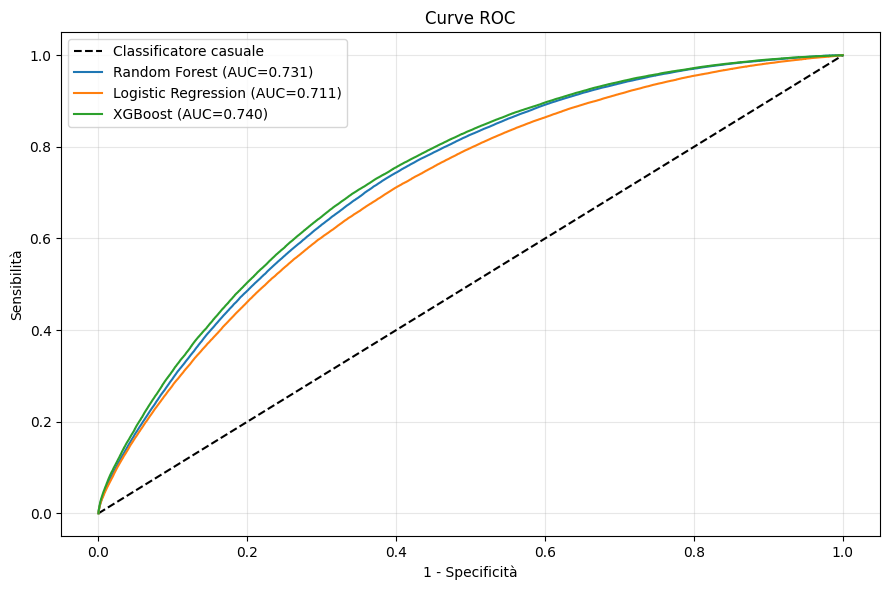

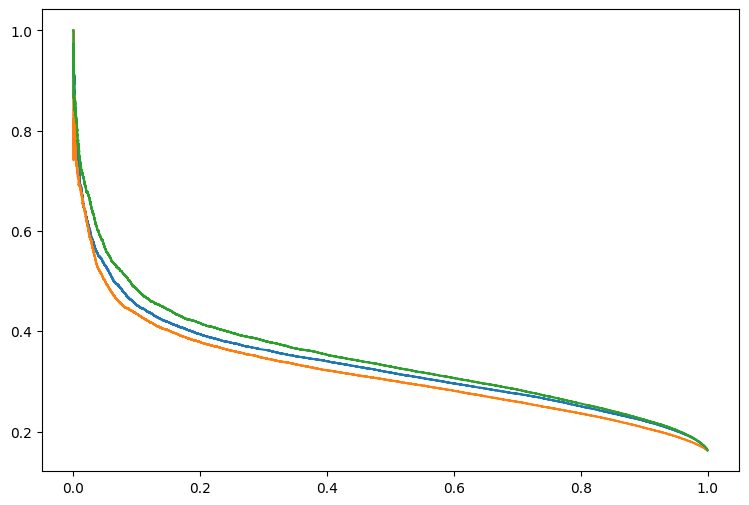

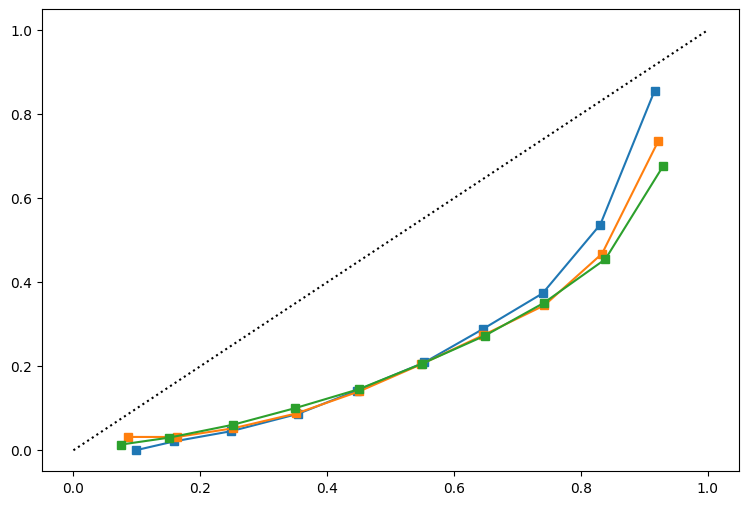

In [12]:
os.makedirs("outputs", exist_ok=True)

risultati = {}
prob_test_per_dca = {}   # salva le probabilità per la DCA

fig_roc, ax_roc = plt.subplots(figsize=(9, 6))
ax_roc.plot([0,1], [0,1], "k--", label="Classificatore casuale")

fig_pr, ax_pr = plt.subplots(figsize=(9, 6))
fig_cal, ax_cal = plt.subplots(figsize=(9, 6))
ax_cal.plot([0,1], [0,1], "k:", label="Perfettamente calibrato")

for nome, modello in modelli.items():
    print(f"\nAddestrando {nome}...")
    if nome == "Logistic Regression":
        modello.fit(X_train_scaled, y_train)
        prob_val  = modello.predict_proba(X_val_scaled)[:, 1]
        prob_test = modello.predict_proba(X_test_scaled)[:, 1]
    else:
        modello.fit(X_train, y_train)
        prob_val  = modello.predict_proba(X_val)[:, 1]
        prob_test = modello.predict_proba(X_test)[:, 1]

    # Soglia ottimale (Youden sul validation set)
    fpr_v, tpr_v, soglie_v = roc_curve(y_val, prob_val)
    soglia_ottimale = soglie_v[np.argmax(tpr_v - fpr_v)]
    # Metriche sul VALIDATION: servono solo a scegliere il modello (il test resta per la valutazione finale)
    auc_val   = roc_auc_score(y_val, prob_val)
    ap_val    = average_precision_score(y_val, prob_val)
    brier_val = brier_score_loss(y_val, prob_val)

    y_pred = (prob_test >= soglia_ottimale).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    auc   = roc_auc_score(y_test, prob_test)
    f1    = f1_score(y_test, y_pred, zero_division=0)
    prec  = precision_score(y_test, y_pred, zero_division=0)
    rec   = recall_score(y_test, y_pred, zero_division=0)
    ap    = average_precision_score(y_test, prob_test)
    spec  = tn / (tn + fp)
    brier = brier_score_loss(y_test, prob_test)

    risultati[nome] = {
        "AUC": round(auc,3), "AUPRC": round(ap,3), "F1": round(f1,3),
        "Sensibilità": round(rec,3), "Specificità": round(spec,3),
        "Precisione": round(prec,3), "Brier Score": round(brier,3),
        "Soglia Youden": round(soglia_ottimale,3),
        "AUC_val": round(auc_val,3), "AUPRC_val": round(ap_val,3), "Brier_val": round(brier_val,3),
    }
    prob_test_per_dca[nome] = prob_test

    print(f"  AUC={auc:.3f} | AUPRC={ap:.3f} | Brier={brier:.3f} | Sensib={rec:.3f}")

    fpr_t, tpr_t, _ = roc_curve(y_test, prob_test)
    ax_roc.plot(fpr_t, tpr_t, label=f"{nome} (AUC={auc:.3f})")

    prec_v, rec_v, _ = precision_recall_curve(y_test, prob_test)
    ax_pr.plot(rec_v, prec_v, label=f"{nome} (AUPRC={ap:.3f})")

    pt, pp = calibration_curve(y_test, prob_test, n_bins=10)
    ax_cal.plot(pp, pt, marker="s", label=f"{nome} (Brier={brier:.3f})")

# Salvataggio grafici ROC e PR
for ax, fig, nome_file, titolo, xlabel, ylabel in [
    (ax_roc, fig_roc, "confronto_roc.png", "Curve ROC", "1 - Specificità", "Sensibilità"),
    (ax_pr,  fig_pr,  "confronto_pr.png",  "Curve Precision-Recall", "Recall", "Precisione"),
]:
    baseline = (y_test == 1).mean()
    if ax is ax_pr:
        ax.axhline(y=baseline, color="k", linestyle="--",
                   label=f"Casuale (AP={baseline:.3f})")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_title(titolo); ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(f"outputs/{nome_file}", dpi=150)
    plt.show(); plt.close(fig)

# Calibrazione
ax_cal.set_xlabel("Probabilità predetta"); ax_cal.set_ylabel("Frequenza osservata")
ax_cal.set_title("Curve di Calibrazione (affidabilità clinica)")
ax_cal.legend(); ax_cal.grid(alpha=0.3)
fig_cal.tight_layout(); fig_cal.savefig("outputs/confronto_calibrazione.png", dpi=150)
plt.show(); plt.close(fig_cal)


## 11. Decision Curve Analysis — DCA (Passo 2.2)

La DCA misura il **net benefit clinico** del modello rispetto a due strategie banali:
- *Tratta tutti*: prescrive la terapia/allerta a tutti i pazienti indipendentemente dal rischio
- *Non trattare nessuno*: non invia mai un allarme

Se la curva del modello supera entrambe le strategie banali, il modello ha **utilità clinica reale**.
Questo è il requisito minimo per considerare un sistema di early warning deployabile in reparto.

Riferimento: Vickers & Elkin, *Medical Decision Making*, 2006.

L'AUC misura se il modello sa distinguere i pazienti a rischio da quelli stabili.
Ma non risponde alla domanda clinica reale:
"Se uso questo modello in reparto e mando un allarme ogni volta che la probabilità supera una certa soglia, sto facendo più bene o più male rispetto a non usarlo?"
A questa domanda risponde la Decision Curve Analysis.



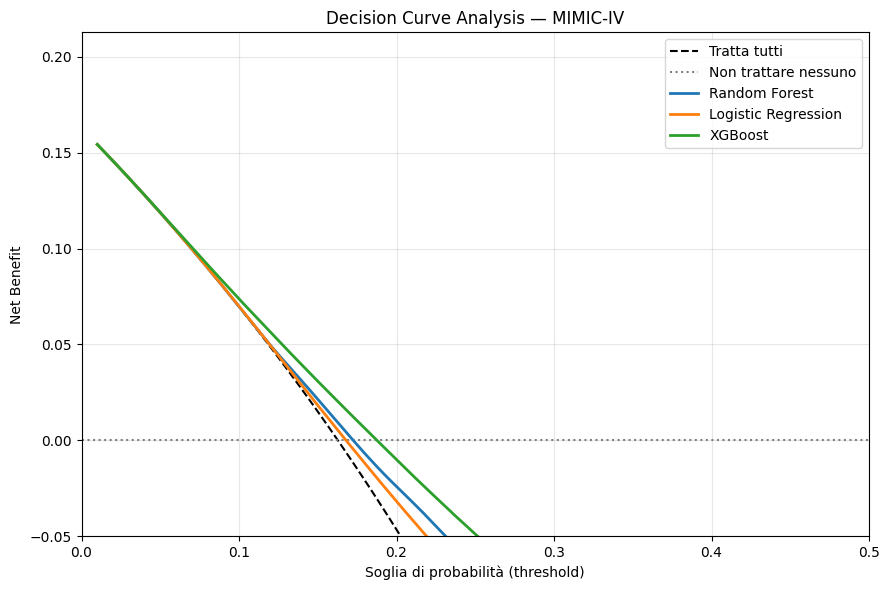

  DCA salvata in outputs/decision_curve_analysis.png


In [13]:
def decision_curve_analysis(y_true, prob_dict, thresholds=None, title="Decision Curve Analysis"):
    """
    Calcola e visualizza la DCA per uno o più modelli.
    Net benefit = TP/n − FP/n × (soglia / (1 − soglia))
    """
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.50, 200)

    n = len(y_true)
    prevalenza = y_true.mean()

    fig, ax = plt.subplots(figsize=(9, 6))

    # Strategia 1: tratta tutti
    nb_tutti = [prevalenza - (1 - prevalenza) * (t / (1 - t)) for t in thresholds]
    ax.plot(thresholds, nb_tutti, "k--", label="Tratta tutti", linewidth=1.5)
    # Strategia 2: non trattare nessuno → net benefit = 0
    ax.axhline(0, color="gray", linestyle=":", label="Non trattare nessuno", linewidth=1.5)

    for nome, prob in prob_dict.items():
        nb_model = []
        for t in thresholds:
            if t >= 1:
                nb_model.append(0)
                continue
            y_pred = (prob >= t).astype(int)
            tp = ((y_pred == 1) & (y_true == 1)).sum()
            fp = ((y_pred == 1) & (y_true == 0)).sum()
            nb = tp / n - fp / n * (t / (1 - t))
            nb_model.append(nb)
        ax.plot(thresholds, nb_model, label=nome, linewidth=2)

    ax.set_xlabel("Soglia di probabilità (threshold)")
    ax.set_ylabel("Net Benefit")
    ax.set_title(title)
    ax.set_xlim(0, 0.5); ax.set_ylim(-0.05, prevalenza + 0.05)
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig("outputs/decision_curve_analysis.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("  DCA salvata in outputs/decision_curve_analysis.png")

decision_curve_analysis(
    y_test.values,
    prob_test_per_dca,
    title="Decision Curve Analysis — MIMIC-IV"
)


## 12. Tabella Riassuntiva e Selezione Modello Migliore

Il modello si sceglie sulla **validazione**, mai sul test, con un punteggio composito:

**40% AUC + 30% AUPRC + 30% (1 − Brier)**

- AUC e AUPRC misurano quanto il modello distingue i pazienti a rischio da quelli stabili (l'AUPRC è più informativa con classi sbilanciate);
- il Brier misura quanto sono affidabili le probabilità, qui ancora **grezze** (prima della ricalibrazione).

Le metriche sul test compaiono nella tabella per completezza, ma non entrano nella scelta.

**Verifica (28/09/2026):** ricalibrando prima tutti e tre i modelli, oppure togliendo il Brier dal punteggio,
su MIMIC-IV vince comunque XGBoost. La ricalibrazione fatta dopo non ha influito sulla scelta
(notebook `verifica_ricalibrazione_mimic.ipynb`).

In [14]:
import joblib

df_risultati = pd.DataFrame(risultati).T

# Punteggio composito: considera tutte e tre le dimensioni
# AUC e AUPRC → più alto è meglio
# Brier Score → più basso è meglio (quindi lo invertiamo)
# Punteggio composito calcolato sul VALIDATION: il test resta solo per la valutazione finale
df_risultati["punteggio_composito"] = (
    df_risultati["AUC_val"].astype(float) * 0.40 +
    df_risultati["AUPRC_val"].astype(float) * 0.30 +
    (1 - df_risultati["Brier_val"].astype(float)) * 0.30
)

df_risultati = df_risultati.sort_values("punteggio_composito", ascending=False)

print("Criteri di selezione:")
print("  40% — AUC          (discriminazione)")
print("  30% — AUPRC        (performance su classi sbilanciate)")
print("  30% — 1-Brier      (calibrazione — affidabilità clinica)")
print("\n" + "="*75)
print("CONFRONTO MODELLI — MIMIC-IV")
print("="*75)
print(df_risultati.to_string())

migliore = df_risultati.index[0]
print(f"\n✓ Modello migliore per punteggio composito (40% AUC + 30% AUPRC + 30% calibrazione): {migliore}")
print(f"  AUC={df_risultati.loc[migliore,'AUC']} | "
      f"AUPRC={df_risultati.loc[migliore,'AUPRC']} | "
      f"Brier={df_risultati.loc[migliore,'Brier Score']} | "
      f"Punteggio composito={df_risultati.loc[migliore,'punteggio_composito']:.4f}")

os.makedirs("models", exist_ok=True)
joblib.dump(modelli[migliore], "models/modello_news2_mimic.pkl")
joblib.dump(scaler, "models/scaler_mimic.pkl")
print("✓ Modello e scaler salvati in models/")


Criteri di selezione:
  40% — AUC          (discriminazione)
  30% — AUPRC        (performance su classi sbilanciate)
  30% — 1-Brier      (calibrazione — affidabilità clinica)

CONFRONTO MODELLI — MIMIC-IV
                       AUC  AUPRC     F1  Sensibilità  Specificità  Precisione  Brier Score  Soglia Youden  AUC_val  AUPRC_val  Brier_val  punteggio_composito
XGBoost              0.740  0.347  0.403        0.707        0.650       0.282        0.206          0.498    0.737      0.321      0.206               0.6293
Random Forest        0.731  0.333  0.395        0.713        0.631       0.273        0.211          0.489    0.730      0.309      0.210               0.6217
Logistic Regression  0.711  0.317  0.381        0.669        0.641       0.266        0.219          0.502    0.710      0.296      0.217               0.6077

✓ Modello migliore per punteggio composito (40% AUC + 30% AUPRC + 30% calibrazione): XGBoost
  AUC=0.74 | AUPRC=0.347 | Brier=0.206 | Punteggio composito=0.

### Confronto con il NEWS-2 usato da solo
Il NEWS-2 è un punteggio: si usa direttamente per ordinare i pazienti (più è alto, più il rischio è alto),
senza addestrare nulla. Calcolando l'AUC sugli **stessi pazienti del test** si confronta il modello con ciò
che si usa già in clinica: è il primo obiettivo della tesi.

Per completezza si confrontano anche altri riferimenti semplici: la media e il massimo del NEWS-2 nelle
ultime 6 ore e il Delta-NEWS a 6 ore usato da solo.

In [15]:
# =============================================================================
# CONFRONTO CON IL NEWS-2 USATO DA SOLO (punto 17)
# Un punteggio singolo si usa direttamente per ordinare i pazienti: più è alto,
# più il rischio è alto. Non serve addestrare nulla, quindi il confronto
# sul test è pulito.
# =============================================================================
from sklearn.metrics import roc_auc_score

X_test_modello = X_test_scaled if migliore == "Logistic Regression" else X_test
prob_modello = modelli[migliore].predict_proba(X_test_modello)[:, 1]

confronto = {
    "NEWS-2 istantaneo (pratica clinica)": X_test["news2"],
    "NEWS-2 media ultime 6h":              X_test["news2_media_6h"],
    "NEWS-2 massimo ultime 6h":            X_test["news2_max_6h"],
    "Delta-NEWS 6h da solo":               X_test["delta_news_6h"],
    f"Modello completo ({migliore})":      prob_modello,
}
print("=" * 60)
print("AUC sul test — MIMIC-IV")
print("=" * 60)
for nome, punteggio in confronto.items():
    print(f"  {nome:38s} {roc_auc_score(y_test, punteggio):.3f}")

AUC sul test — MIMIC-IV


  NEWS-2 istantaneo (pratica clinica)    0.665


  NEWS-2 media ultime 6h                 0.678
  NEWS-2 massimo ultime 6h               0.673


  Delta-NEWS 6h da solo                  0.523


  Modello completo (XGBoost)             0.740


## 13. Explainable AI — SHAP (Passo 2.3)
Il beeswarm plot mostra quali feature influenzano di più la predizione e in quale direzione.
Serve a verificare che il modello si basi su associazioni clinicamente plausibili (per esempio NEWS-2 più alto →
rischio più alto) e non su artefatti dei dati.

Nota di lettura: nel lavoro il Delta-NEWS **non** è risultato tra le variabili più influenti (anche usato da solo
ha un'AUC vicina al caso), quindi non va presentato come il fattore principale del modello.

Calcolo valori SHAP (potrebbe richiedere 1-2 minuti)...


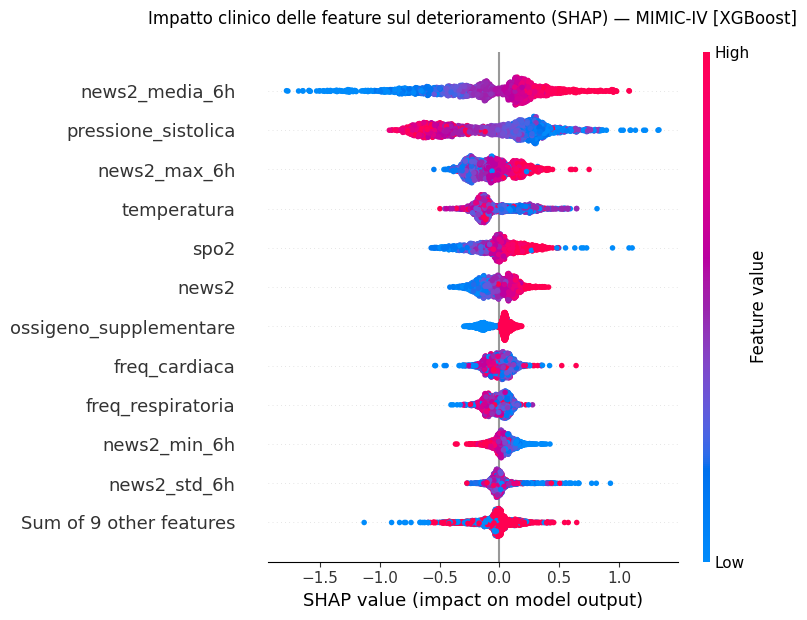

✓ SHAP salvato in outputs/shap_beeswarm_mimic.png


In [16]:
import shap

print("Calcolo valori SHAP (potrebbe richiedere 1-2 minuti)...")

# Modello migliore per punteggio composito (prima era fissato a Random Forest)
if migliore == "Logistic Regression":
    X_test_shap  = pd.DataFrame(X_test_scaled,  columns=FEATURES, index=X_test.index)
    X_train_shap = pd.DataFrame(X_train_scaled, columns=FEATURES, index=X_train.index)
    esploratore = shap.Explainer(modelli[migliore], X_train_shap)
else:
    X_test_shap = X_test
    esploratore = shap.Explainer(modelli[migliore])
X_campione  = X_test_shap.sample(min(2000, len(X_test_shap)), random_state=42)
valori_shap = esploratore(X_campione)

plt.figure(figsize=(10, 8))
valori_da_plottare = valori_shap[:, :, 1] if valori_shap.values.ndim == 3 else valori_shap
shap.plots.beeswarm(valori_da_plottare, max_display=12, show=False)
plt.title(f"Impatto clinico delle feature sul deterioramento (SHAP) — MIMIC-IV [{migliore}]", pad=20)
plt.tight_layout()
plt.savefig("outputs/shap_beeswarm_mimic.png", dpi=150)
plt.show()
print("✓ SHAP salvato in outputs/shap_beeswarm_mimic.png")


## 14. Intervallo di confidenza al 95% — bootstrap per paziente (Passo 2.4)
Il test è un gruppo di pazienti scelto a caso: con un altro gruppo simile l'AUC sarebbe un po' diversa.
L'intervallo di confidenza al 95% dice **di quanto**, cioè quanto è stabile il risultato.

Si calcola **alla fine, solo sul modello già scelto** e solo sui pazienti del test: non serve a scegliere il
modello (la scelta è già stata fatta sulla validazione).

**Procedimento (bootstrap):**
1. dai pazienti del test se ne estrae a caso lo stesso numero, **con reinserimento** (lo stesso paziente può uscire più volte, un altro nessuna);
2. si ricalcola l'AUC su questo nuovo gruppo;
3. si ripete 1.000 volte: l'intervallo al 95% va dal 2,5° al 97,5° percentile delle 1.000 AUC.

Non si aggiungono pazienti nuovi, non si modificano i dati e non si riaddestra il modello: cambia solo quali
pazienti contano.

**Ricampionamento per paziente.** Il test set contiene molte righe per ogni paziente (una ogni 10 minuti), fortemente correlate tra loro. Il bootstrap quindi ricampiona i **pazienti** (con reinserimento) e per ciascuno tiene tutte le sue righe: è il cosiddetto *cluster bootstrap*. Ricampionare le singole righe tratterebbe come indipendenti misure che non lo sono e produrrebbe intervalli di confidenza artificialmente stretti (circa ±0,001 invece di circa ±0,01).

**Come si legge:** un intervallo stretto vuol dire che il risultato non dipende da quali pazienti sono capitati
nel test. Se gli intervalli di due database si sovrappongono quasi del tutto, la differenza tra le due AUC non
va considerata reale. L'intervallo non dice se il modello funziona in altri ospedali: questo lo mostra il
confronto tra i tre database.

In [17]:
from sklearn.utils import resample

print("Calcolo 95% CI via bootstrapping (1000 iterazioni)...")

# Usa il modello migliore selezionato dal punteggio composito
if migliore == "Logistic Regression":
    prob_migliore = modelli[migliore].predict_proba(X_test_scaled)[:, 1]
else:
    prob_migliore = modelli[migliore].predict_proba(X_test)[:, 1]

# Bootstrap PER PAZIENTE (cluster bootstrap): si ricampionano i pazienti del test set con
# reinserimento e si tengono tutte le loro righe. Le righe dello stesso paziente sono molto simili
# tra loro (una ogni 10 minuti): ricampionare le singole righe, come si faceva prima, trattava come
# indipendenti misure che non lo sono e dava intervalli falsamente stretti (circa +-0,001).
# Un paziente estratto k volte pesa k volte: lo si ottiene con sample_weight, senza copiare le righe.
id_test = np.asarray(df_test["subject_id"])                             # subject_id di ogni riga del test set
codici_paz, pazienti_test = pd.factorize(id_test)           # ogni subject_id -> un numero 0..N-1
n_paz = len(pazienti_test)
y_boot = np.asarray(y_test)
rng_boot = np.random.default_rng(42)

punteggi_auc_bootstrap = []
for i in range(1000):
    estratti = rng_boot.integers(0, n_paz, n_paz)                 # N pazienti estratti con reinserimento
    peso = np.bincount(estratti, minlength=n_paz)[codici_paz]      # quante volte e' stato estratto il paziente di ogni riga
    tenute = peso > 0
    if len(np.unique(y_boot[tenute])) < 2:
        continue
    punteggi_auc_bootstrap.append(
        roc_auc_score(y_boot[tenute], prob_migliore[tenute], sample_weight=peso[tenute]))

limite_inferiore = np.percentile(punteggi_auc_bootstrap, 2.5)
limite_superiore = np.percentile(punteggi_auc_bootstrap, 97.5)
auc_originale = roc_auc_score(y_boot, prob_migliore)

print("="*60)
print(f"RISULTATI STATISTICI - {migliore} (Test Set) — MIMIC-IV")
print("="*60)
print(f"Pazienti nel test set: {n_paz:,} | righe: {len(y_boot):,}")
print(f"AUC puntuale: {auc_originale:.3f}")
print(f"95% CI (bootstrap per paziente, 1000 iterazioni): [{limite_inferiore:.3f} - {limite_superiore:.3f}]")
print("="*60)
print()
print("✓ MIMIC-IV completato.")


Calcolo 95% CI via bootstrapping (1000 iterazioni)...


RISULTATI STATISTICI - XGBoost (Test Set) — MIMIC-IV
Pazienti nel test set: 4,000 | righe: 578,376
AUC puntuale: 0.740
95% CI (bootstrap per paziente, 1000 iterazioni): [0.729 - 0.750]

✓ MIMIC-IV completato.


### Ricalibrazione delle probabilità (isotonic regression)
Le curve di calibrazione mostrano che il modello **sovrastima** il rischio: la probabilità predetta è più alta
della frequenza osservata su quasi tutto l'intervallo (Brier peggiore del Brier banale della sola prevalenza).
È l'effetto atteso di `class_weight='balanced'` / `scale_pos_weight`: in addestramento i casi di
deterioramento, che sono pochi, pesano di più, e il modello impara come se fossero circa la metà.

Correggiamo con una **regressione isotonica**: una trasformazione monotona appresa SOLO sul validation set
(mai sul test, per non introdurre data leakage) che mappa la probabilità grezza del modello nella probabilità
calibrata. L'AUC non cambia per costruzione (la trasformazione è monotona, non altera l'ordinamento dei
pazienti per rischio): cambia solo l'affidabilità del numero, utile per un'eventuale soglia clinica basata sul
rischio assoluto e non solo sul ranking.

La ricalibrazione si applica **dopo** la scelta del modello e solo al modello scelto. È stato verificato che,
ricalibrando prima tutti e tre i modelli, la scelta non cambia.

RICALIBRAZIONE (isotonic, adattata sul validation) — XGBoost
Brier PRIMA della ricalibrazione : 0.2065
Brier DOPO  la ricalibrazione    : 0.1224
AUC   PRIMA della ricalibrazione : 0.7400
AUC   DOPO  la ricalibrazione    : 0.7399  (invariata per costruzione, a meno di pareggi)


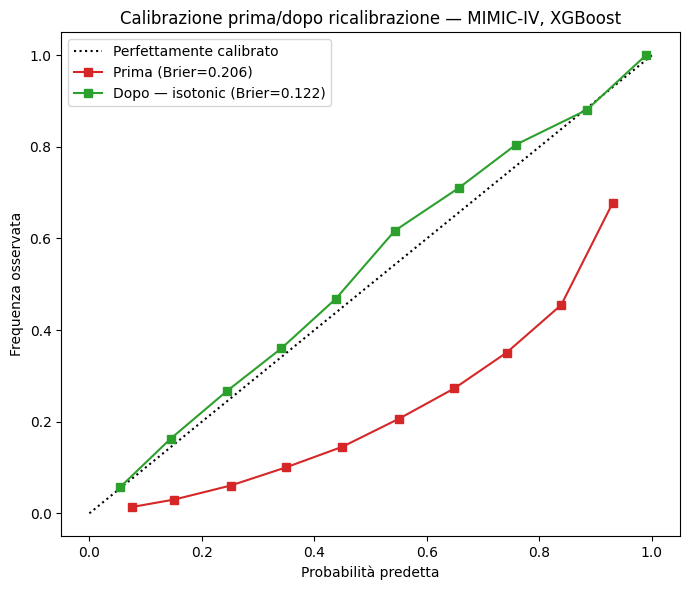


OK - Regressione isotonica salvata in models/isotonic_mimic.pkl
Per una probabilita' calibrata: calibratore.predict(modello.predict_proba(X)[:, 1])


In [18]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

modello_sel = modelli[migliore]
X_val_per_cal  = X_val_scaled  if migliore == 'Logistic Regression' else X_val
X_test_per_cal = X_test_scaled if migliore == 'Logistic Regression' else X_test

prob_val_migliore  = modello_sel.predict_proba(X_val_per_cal)[:, 1]
prob_test_migliore = modello_sel.predict_proba(X_test_per_cal)[:, 1]

calibratore = IsotonicRegression(out_of_bounds="clip")
calibratore.fit(prob_val_migliore, y_val)   # la mappa si impara SOLO sul validation, mai sul test

prob_test_calibrata = calibratore.predict(prob_test_migliore)

brier_prima = brier_score_loss(y_test, prob_test_migliore)
brier_dopo  = brier_score_loss(y_test, prob_test_calibrata)
auc_prima   = roc_auc_score(y_test, prob_test_migliore)
auc_dopo    = roc_auc_score(y_test, prob_test_calibrata)

print("=" * 60)
print(f"RICALIBRAZIONE (isotonic, adattata sul validation) — {migliore}")
print("=" * 60)
print(f"Brier PRIMA della ricalibrazione : {brier_prima:.4f}")
print(f"Brier DOPO  la ricalibrazione    : {brier_dopo:.4f}")
print(f"AUC   PRIMA della ricalibrazione : {auc_prima:.4f}")
print(f"AUC   DOPO  la ricalibrazione    : {auc_dopo:.4f}  (invariata per costruzione, a meno di pareggi)")
print("=" * 60)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k:", label="Perfettamente calibrato")
pt0, pp0 = calibration_curve(y_test, prob_test_migliore, n_bins=10)
pt1, pp1 = calibration_curve(y_test, prob_test_calibrata, n_bins=10)
ax.plot(pp0, pt0, "s-", color="tab:red", label=f"Prima (Brier={brier_prima:.3f})")
ax.plot(pp1, pt1, "s-", color="tab:green", label=f"Dopo — isotonic (Brier={brier_dopo:.3f})")
ax.set_xlabel("Probabilità predetta"); ax.set_ylabel("Frequenza osservata")
ax.set_title(f"Calibrazione prima/dopo ricalibrazione — MIMIC-IV, {migliore}")
ax.legend(); plt.tight_layout()
plt.savefig("outputs/calibrazione_isotonic_mimic.png", dpi=150)
plt.show()

joblib.dump(calibratore, "models/isotonic_mimic.pkl")
print()
print("OK - Regressione isotonica salvata in models/isotonic_mimic.pkl")
print("Per una probabilita' calibrata: calibratore.predict(modello.predict_proba(X)[:, 1])")


### Decision Curve Analysis sulle probabilità calibrate
La DCA confronta il **beneficio netto** del modello con due strategie banali: dare l'allarme a tutti o a nessuno
(Vickers & Elkin, *Medical Decision Making*, 2006). Nella DCA la soglia è un rischio assoluto
("intervengo sopra il 20%"), quindi servono probabilità calibrate: si usa il modello scelto dopo la
ricalibrazione isotonica.

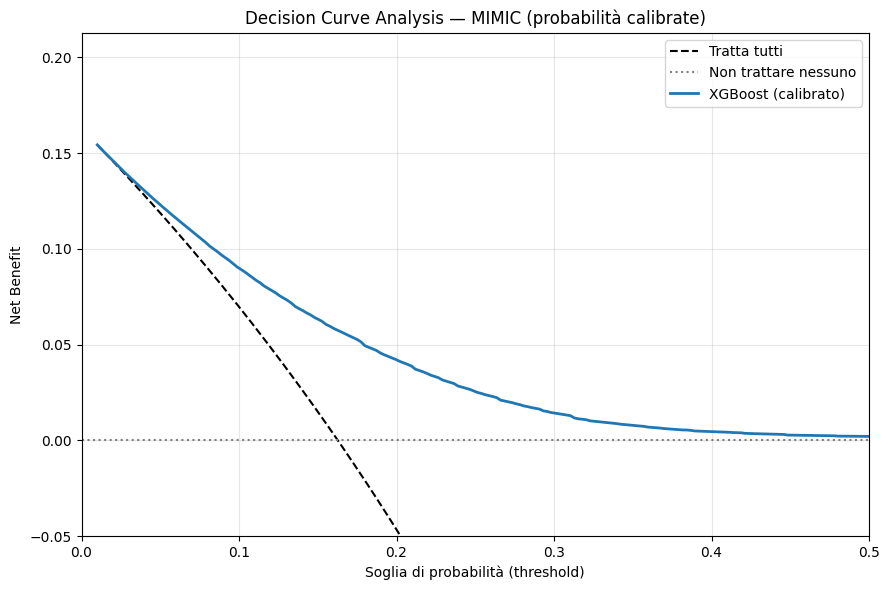

  DCA salvata in outputs/decision_curve_analysis.png


In [19]:
# =============================================================================
# DECISION CURVE ANALYSIS SULLE PROBABILITÀ CALIBRATE
# Nella DCA la soglia è un rischio vero ("intervengo sopra il 20%"), quindi
# servono probabilità calibrate. Si usa il modello migliore dopo la
# ricalibrazione isotonica (adattata solo sul validation).
# =============================================================================
decision_curve_analysis(
    y_test.values,
    {f"{migliore} (calibrato)": prob_test_calibrata},
    title="Decision Curve Analysis — MIMIC (probabilità calibrate)"
)

### Tempo di anticipo degli allarmi
L'AUC valuta ogni blocco di 10 minuti. Un medico però chiede: **quanto prima mi avvisa il sistema, per ogni evento?**
Per ogni evento dei pazienti del test (morte, inizio di un vasopressore, intubazione) si guardano le **24 ore precedenti**,
la stessa finestra dell'etichetta:
- l'evento è **intercettato** se in quelle 24 ore il modello supera almeno una volta la soglia di allarme (Youden, scelta sulla validazione);
- l'**anticipo** è il tempo tra il **primo** allarme della finestra e l'evento (massimo 24 ore);
- gli eventi senza nessuna osservazione nelle 24 ore precedenti (per esempio all'inizio del ricovero) non sono valutabili e sono contati a parte.

Si usa il modello già scelto, sulle probabilità grezze e con la stessa soglia: nessun nuovo addestramento, nessun risultato precedente cambia.
La misura "eventi segnalati con almeno 2 ore di anticipo" è confrontabile con Hyland et al., Nature Medicine 2020.

Per leggere correttamente questi numeri servono due confronti, calcolati nella stessa cella:
- **falsi allarmi**: nei ricoveri senza nessun evento, quanti ricevono comunque almeno un allarme e per quanta parte del tempo;
- **NEWS-2 come riferimento**: la stessa misura con le soglie cliniche del NEWS-2 (5 = risposta urgente, 7 = emergenza).


In [20]:
# =============================================================================
# TEMPO DI ANTICIPO DEGLI ALLARMI (analisi aggiunta, non cambia i risultati precedenti)
# =============================================================================
from sklearn.metrics import roc_curve

def tempo_di_anticipo(righe, eventi, chiavi, soglia, finestra_ore=24):
    # righe: chiavi + "t" (ore) + "prob"; eventi: chiavi + "t_evento" (ore) + "tipo_evento"
    eventi = eventi.drop_duplicates(chiavi + ["t_evento", "tipo_evento"]).reset_index(drop=True)
    eventi["id_evento"] = eventi.index
    m = eventi.merge(righe, on=chiavi, how="inner")
    m = m[(m["t"] < m["t_evento"]) & (m["t"] >= m["t_evento"] - finestra_ore)]   # solo le 24 ore PRIMA dell'evento
    per_evento = m.groupby("id_evento").agg(tipo=("tipo_evento", "first"), t_evento=("t_evento", "first"))
    per_evento["t_primo_allarme"] = m[m["prob"] >= soglia].groupby("id_evento")["t"].min()
    per_evento["anticipo_ore"] = per_evento["t_evento"] - per_evento["t_primo_allarme"]   # NaN = nessun allarme = evento mancato
    return per_evento, len(eventi)

def riassunto_anticipo(per_evento, n_eventi, nome_db):
    intercettato = per_evento["anticipo_ore"].notna()
    almeno_2h = per_evento["anticipo_ore"] >= 2
    anticipi = per_evento.loc[intercettato, "anticipo_ore"]
    print("=" * 70)
    print(f"TEMPO DI ANTICIPO DEGLI ALLARMI — {nome_db}")
    print("=" * 70)
    print(f"Eventi nei pazienti del test:                        {n_eventi:,}")
    print(f"Valutabili (almeno un'osservazione nelle 24 h prima): {len(per_evento):,}")
    print(f"Intercettati (almeno un allarme nelle 24 h prima):    {int(intercettato.sum()):,} ({100 * intercettato.mean():.1f}%)")
    print(f"Segnalati con almeno 2 ore di anticipo:               {int(almeno_2h.sum()):,} ({100 * almeno_2h.mean():.1f}%)")
    print(f"Anticipo del primo allarme (eventi intercettati): mediana {anticipi.median():.1f} ore, "
          f"IQR {anticipi.quantile(0.25):.1f}-{anticipi.quantile(0.75):.1f} ore")
    per_tipo = (per_evento.assign(intercettato=intercettato, almeno_2h=almeno_2h)
                .groupby("tipo")
                .agg(eventi=("intercettato", "size"),
                     intercettati_pct=("intercettato", "mean"),
                     almeno_2h_pct=("almeno_2h", "mean"),
                     anticipo_mediano_ore=("anticipo_ore", "median")))
    per_tipo[["intercettati_pct", "almeno_2h_pct"]] = (100 * per_tipo[["intercettati_pct", "almeno_2h_pct"]]).round(1)
    per_tipo["anticipo_mediano_ore"] = per_tipo["anticipo_mediano_ore"].round(1)
    print()
    print("Per tipo di evento:")
    print(per_tipo.to_string())
    print("=" * 70)

def carico_allarmi(righe, eventi, chiavi, soglia, nome):
    # Falsi allarmi: nei ricoveri SENZA nessun evento, quanto spesso il sistema dà comunque l'allarme?
    con_eventi = eventi[chiavi].drop_duplicates()
    senza = righe.merge(con_eventi.assign(_ev=1), on=chiavi, how="left")
    senza = senza[senza["_ev"].isna()]
    in_allarme = senza["prob"] >= soglia
    ricoveri_con_allarme = in_allarme.groupby([senza[k] for k in chiavi]).any()
    print(f"  {nome}: ricoveri senza eventi {ricoveri_con_allarme.size:,}; "
          f"con almeno un allarme {100 * ricoveri_con_allarme.mean():.1f}%; "
          f"tempo in allarme {100 * in_allarme.mean():.1f}% dei blocchi")

def confronto_con_news2(righe, eventi, chiavi, soglia_modello):
    # Stessa misura con il modello e con le soglie cliniche del NEWS-2 (5 = risposta urgente, 7 = emergenza)
    print()
    print("CONFRONTO CON IL NEWS-2 (stessi eventi, stessa finestra di 24 ore)")
    righe_news = righe.assign(prob=righe["news2"])
    riga = []
    for nome, r, s in [("Modello", righe, soglia_modello), ("NEWS-2 >= 5", righe_news, 5), ("NEWS-2 >= 7", righe_news, 7)]:
        pe, _ = tempo_di_anticipo(r[chiavi + ["t", "prob"]], eventi, chiavi, s)
        intercettato = pe["anticipo_ore"].notna()
        riga.append({"allarme": nome,
                     "intercettati_%": round(100 * intercettato.mean(), 1),
                     "almeno_2h_%": round(100 * (pe["anticipo_ore"] >= 2).mean(), 1),
                     "anticipo_mediano_ore": round(pe.loc[intercettato, "anticipo_ore"].median(), 1)})
    print(pd.DataFrame(riga).to_string(index=False))
    print()
    print("FALSI ALLARMI (ricoveri del test senza nessun evento)")
    carico_allarmi(righe, eventi, chiavi, soglia_modello, "Modello    ")
    carico_allarmi(righe_news, eventi, chiavi, 5, "NEWS-2 >= 5")
    carico_allarmi(righe_news, eventi, chiavi, 7, "NEWS-2 >= 7")

def ore(tempi):
    # istanti di tempo -> ore (numero), per poter fare differenze semplici
    return pd.to_datetime(tempi).astype("int64") / 3.6e12

# Soglia di allarme del modello migliore, ricalcolata sulla validazione come nel ciclo di addestramento
fpr_v, tpr_v, soglie_v = roc_curve(y_val, prob_val_migliore)
soglia_allarme = soglie_v[np.argmax(tpr_v - fpr_v)]
print(f"Soglia di allarme ({migliore}): {soglia_allarme:.3f}")

# Orari delle righe del test: df_test conserva l'indice di df
righe_test = df.loc[df_test.index, ["subject_id", "stay_id", "charttime"]].reset_index(drop=True)
assert (righe_test["subject_id"].values == df_test["subject_id"].values).all(), "ordine delle righe diverso dal test"
righe_test["t"] = ore(righe_test["charttime"])
righe_test["prob"] = prob_test_migliore
righe_test["news2"] = X_test["news2"].values

eventi_test = tutti_eventi.dropna(subset=["evento_time"])
eventi_test = eventi_test[eventi_test["subject_id"].isin(test_ids)].copy()
eventi_test["t_evento"] = ore(eventi_test["evento_time"])

per_evento, n_eventi = tempo_di_anticipo(righe_test[["subject_id", "stay_id", "t", "prob"]],
                                         eventi_test[["subject_id", "stay_id", "t_evento", "tipo_evento"]],
                                         ["subject_id", "stay_id"], soglia_allarme)
riassunto_anticipo(per_evento, n_eventi, "MIMIC-IV")
confronto_con_news2(righe_test, eventi_test[["subject_id", "stay_id", "t_evento", "tipo_evento"]], ["subject_id", "stay_id"], soglia_allarme)


Soglia di allarme (XGBoost): 0.498


TEMPO DI ANTICIPO DEGLI ALLARMI — MIMIC-IV
Eventi nei pazienti del test:                        7,151
Valutabili (almeno un'osservazione nelle 24 h prima): 6,600
Intercettati (almeno un allarme nelle 24 h prima):    6,402 (97.0%)
Segnalati con almeno 2 ore di anticipo:               4,400 (66.7%)
Anticipo del primo allarme (eventi intercettati): mediana 19.2 ore, IQR 0.6-23.4 ore

Per tipo di evento:
              eventi  intercettati_pct  almeno_2h_pct  anticipo_mediano_ore
tipo                                                                       
intubazione     1763              94.5           32.4                   0.4
morte_icu        457              99.6           98.2                  23.2
vasopressore    4380              97.7           77.1                  22.7

CONFRONTO CON IL NEWS-2 (stessi eventi, stessa finestra di 24 ore)


    allarme  intercettati_%  almeno_2h_%  anticipo_mediano_ore
    Modello            97.0         66.7                  19.2
NEWS-2 >= 5            81.9         66.8                  23.1
NEWS-2 >= 7            71.9         63.0                  22.4

FALSI ALLARMI (ricoveri del test senza nessun evento)
  Modello    : ricoveri senza eventi 3,342; con almeno un allarme 83.6%; tempo in allarme 21.5% dei blocchi
  NEWS-2 >= 5: ricoveri senza eventi 3,342; con almeno un allarme 83.6%; tempo in allarme 43.2% dei blocchi


  NEWS-2 >= 7: ricoveri senza eventi 3,342; con almeno un allarme 61.9%; tempo in allarme 21.2% dei blocchi


### Consensus dei tre modelli (ensemble)
Proposta del professore (30 settembre 2026): invece di scegliere un solo modello, si mettono insieme le risposte dei tre
(regressione logistica, Random Forest, XGBoost) per arrivare a una risposta sola. Nessun riaddestramento.
- Ogni modello viene prima ricalibrato (isotonica, sul validation): le tre probabilità finiscono sulla stessa scala
- **Media**: media semplice delle tre probabilità (soft voting)
- **Media pesata**: pesi scelti sul validation con lo stesso punteggio composito usato per scegliere il modello
- **Voto a maggioranza**: allarme se almeno 2 modelli su 3 superano la propria soglia di Youden
- Confronto sul test con il modello scelto, ricalibrato allo stesso modo; differenza di AUC con bootstrap per paziente appaiato

In [21]:
# =============================================================================
# CONSENSUS (ENSEMBLE) DEI TRE MODELLI — MIMIC-IV
# =============================================================================
# Invece di tenere un solo modello, si combinano le risposte dei tre gia' addestrati
# (nessun riaddestramento). Ogni modello viene prima ricalibrato con la regressione isotonica
# sul validation, cosi' le tre probabilita' sono sulla stessa scala; poi:
#   1) MEDIA       = media semplice delle tre probabilita' calibrate (soft voting)
#   2) MEDIA PESATA = pesi scelti sul validation con il punteggio composito (stesso criterio
#                    usato per scegliere il modello); il test resta cieco
#   3) VOTO        = numero di modelli in allarme (0-3), ciascuno con la sua soglia di Youden
#                    scelta sul validation; allarme del consensus = almeno 2 su 3 (maggioranza)
# Il confronto sul test e' con il modello scelto oggi; la differenza di AUC ha un intervallo
# di confidenza con bootstrap per paziente APPAIATO (stessi pazienti estratti per i due modelli).
import itertools
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, confusion_matrix

COLONNA_ID = "subject_id"   # unita' del bootstrap: paziente (persona in eICU-CRD)

def _prob(nome, X, X_sc):
    return modelli[nome].predict_proba(X_sc if nome == "Logistic Regression" else X)[:, 1]

nomi = list(modelli.keys())
cal_val, cal_test, soglie = {}, {}, {}
for nome in nomi:
    pv, pt = _prob(nome, X_val, X_val_scaled), _prob(nome, X_test, X_test_scaled)
    iso = IsotonicRegression(out_of_bounds="clip").fit(pv, y_val)   # mappa imparata solo sul validation
    cal_val[nome], cal_test[nome] = iso.predict(pv), iso.predict(pt)
    fpr, tpr, thr = roc_curve(y_val, pv)
    soglie[nome] = (thr[np.argmax(tpr - fpr)], pv, pt)              # soglia di Youden sul validation (prob. grezze)

def _pesa(w, probs):   # somma pesata; clip per gli arrotondamenti (1.0000000000000002)
    return np.clip(sum(w_i * probs[n] for w_i, n in zip(w, nomi)), 0, 1)

def _composito(y, p):
    return 0.40 * roc_auc_score(y, p) + 0.30 * average_precision_score(y, p) + 0.30 * (1 - brier_score_loss(y, p))

# 1) Media semplice
media_val  = np.mean([cal_val[n] for n in nomi], axis=0)
media_test = np.mean([cal_test[n] for n in nomi], axis=0)

# 2) Media pesata: griglia di pesi a passi di 0,1 che sommano a 1, scelta sul validation
griglia = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(nomi)) if abs(sum(w) - 1) < 1e-9]
punteggi = [(_composito(y_val, _pesa(w, cal_val)), w) for w in griglia]
_, pesi = max(punteggi, key=lambda t: t[0])
pesata_test = _pesa(pesi, cal_test)

# 3) Voto: quanti modelli sono in allarme
voti_test = sum((soglie[n][2] >= soglie[n][0]).astype(int) for n in nomi)

# Modello scelto oggi, calibrato allo stesso modo (riferimento del confronto)
rif_test = cal_test[migliore]

def _riga(nome_riga, p, allarme=None):
    if allarme is None:   # soglia di Youden scelta sul validation per le probabilita' continue
        p_val = {"Modello scelto": cal_val[migliore], "Media": media_val,
                 "Media pesata": _pesa(pesi, cal_val)}[nome_riga.split(" (")[0]]
        fpr, tpr, thr = roc_curve(y_val, p_val)
        allarme = (p >= thr[np.argmax(tpr - fpr)]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, allarme).ravel()
    return {"AUC": roc_auc_score(y_test, p), "AUPRC": average_precision_score(y_test, p),
            "Brier": brier_score_loss(y_test, p) if p.max() <= 1 else np.nan,
            "Sensibilita": tp / (tp + fn), "Specificita": tn / (tn + fp)}

tabella = pd.DataFrame({
    f"Modello scelto ({migliore})": _riga("Modello scelto", rif_test),
    "Media": _riga("Media", media_test),
    "Media pesata": _riga("Media pesata", pesata_test),
    "Voto a maggioranza (>=2 su 3)": _riga("Voto", voti_test.astype(float), allarme=(voti_test >= 2).astype(int)),
}).T

# Bootstrap per paziente appaiato: differenza di AUC (consensus - modello scelto)
id_righe = np.asarray(df_test[COLONNA_ID])
codici, unici = pd.factorize(id_righe)
y_arr = np.asarray(y_test)
rng_c = np.random.default_rng(42)
diff_media, diff_pesata = [], []
for _ in range(1000):
    peso = np.bincount(rng_c.integers(0, len(unici), len(unici)), minlength=len(unici))[codici]
    k = peso > 0
    if len(np.unique(y_arr[k])) < 2:
        continue
    a_rif = roc_auc_score(y_arr[k], rif_test[k], sample_weight=peso[k])
    diff_media.append(roc_auc_score(y_arr[k], media_test[k], sample_weight=peso[k]) - a_rif)
    diff_pesata.append(roc_auc_score(y_arr[k], pesata_test[k], sample_weight=peso[k]) - a_rif)

print("=" * 78)
print("CONSENSUS DEI TRE MODELLI — MIMIC-IV (test set, probabilita' ricalibrate sul validation)")
print("=" * 78)
print("Pesi della media pesata (scelti sul validation): " + ", ".join(f"{n} {w:.1f}" for n, w in zip(nomi, pesi)))
print(tabella.round(3).to_string())
print("-" * 78)
for nome_d, d in [("Media", diff_media), ("Media pesata", diff_pesata)]:
    print(f"Differenza di AUC {nome_d} - modello scelto: {np.mean(d):+.4f}  "
          f"95% CI [{np.percentile(d, 2.5):+.4f} ; {np.percentile(d, 97.5):+.4f}]  (bootstrap per paziente, appaiato)")
print("Se l'intervallo contiene lo 0, il consensus non e' distinguibile dal modello scelto.")
tabella.to_csv("outputs/consensus_mimic.csv")
print("Tabella salvata in outputs/consensus_mimic.csv")


CONSENSUS DEI TRE MODELLI — MIMIC-IV (test set, probabilita' ricalibrate sul validation)
Pesi della media pesata (scelti sul validation): Random Forest 0.2, Logistic Regression 0.1, XGBoost 0.7
                                 AUC  AUPRC  Brier  Sensibilita  Specificita
Modello scelto (XGBoost)       0.740  0.344  0.122        0.707        0.650
Media                          0.737  0.339  0.123        0.719        0.634
Media pesata                   0.741  0.347  0.122        0.711        0.647
Voto a maggioranza (>=2 su 3)  0.697  0.262    NaN        0.705        0.642
------------------------------------------------------------------------------
Differenza di AUC Media - modello scelto: -0.0032  95% CI [-0.0053 ; -0.0011]  (bootstrap per paziente, appaiato)
Differenza di AUC Media pesata - modello scelto: +0.0009  95% CI [+0.0000 ; +0.0018]  (bootstrap per paziente, appaiato)
Se l'intervallo contiene lo 0, il consensus non e' distinguibile dal modello scelto.
Tabella salvata in out